In [1]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns 
import joblib

from sklearn.model_selection import train_test_split , RepeatedStratifiedKFold , cross_validate , cross_val_score , cross_val_predict , GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler , OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier , GradientBoostingClassifier
from sklearn.metrics import classification_report , ConfusionMatrixDisplay , RocCurveDisplay , PrecisionRecallDisplay , roc_auc_score , f1_score , precision_score , recall_score , accuracy_score
from sklearn.inspection import permutation_importance

In [2]:
df = pd.read_csv(r"archive\WA_Fn-UseC_-Telco-Customer-Churn.csv")

In [3]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
df.tail()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes
7042,3186-AJIEK,Male,0,No,No,66,Yes,No,Fiber optic,Yes,...,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),105.65,6844.5,No


In [5]:
df.shape

(7043, 21)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [7]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [8]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

### **Data Cleaning**

In [9]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
df['customerID'].duplicated().sum()

np.int64(0)

In [12]:
df[df['TotalCharges'].str.strip() == ''][['tenure' , 'MonthlyCharges' , 'TotalCharges' , 'Churn']]

,tenure,MonthlyCharges,TotalCharges,Churn
488,0,52.55,,No
753,0,20.25,,No
936,0,80.85,,No
1082,0,25.75,,No
1340,0,56.05,,No
3331,0,19.85,,No
3826,0,25.35,,No
4380,0,20.00,,No
5218,0,19.70,,No
6670,0,73.35,,No


In [13]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'] , errors= 'coerce')
df['TotalCharges'].isnull().sum()

np.int64(11)

In [14]:
df['TotalCharges'] = df['TotalCharges'].fillna(0)
df['TotalCharges'].isnull().sum()

np.int64(0)

In [15]:
df.drop(columns= 'customerID' , inplace= True)
df.shape

(7043, 20)

In [16]:
cat_check = ['MultipleLines' , 'OnlineSecurity' , 'OnlineBackup' , 'DeviceProtection' , 'TechSupport' , 'StreamingTV' , 'StreamingMovies']

for col in cat_check:
    print(col , df[col].unique())

MultipleLines ['No phone service' 'No' 'Yes']
OnlineSecurity ['No' 'Yes' 'No internet service']
OnlineBackup ['Yes' 'No' 'No internet service']
DeviceProtection ['No' 'Yes' 'No internet service']
TechSupport ['No' 'Yes' 'No internet service']
StreamingTV ['No' 'Yes' 'No internet service']
StreamingMovies ['No' 'Yes' 'No internet service']


In [17]:
df.replace({'No internet service': 'No' , 'No phone service': 'No'} , inplace= True)

for col in cat_check:
    print(col , df[col].unique())

MultipleLines ['No' 'Yes']
OnlineSecurity ['No' 'Yes']
OnlineBackup ['Yes' 'No']
DeviceProtection ['No' 'Yes']
TechSupport ['No' 'Yes']
StreamingTV ['No' 'Yes']
StreamingMovies ['No' 'Yes']


In [18]:
df['Churn'] = df['Churn'].map({'No': 0 , 'Yes': 1})
df['Churn'].value_counts()

Churn
0    5174
1    1869
Name: count, dtype: int64

In [19]:
num_cols = ['tenure' , 'MonthlyCharges' , 'TotalCharges']
df[num_cols].describe()

,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000
mean,32.371149,64.761692,2279.734304
std,24.559481,30.090047,2266.794470
min,0.000000,18.250000,0.000000
25%,9.000000,35.500000,398.550000
50%,29.000000,70.350000,1394.550000
75%,55.000000,89.850000,3786.600000
max,72.000000,118.750000,8684.800000


### **EDA && Visualization**

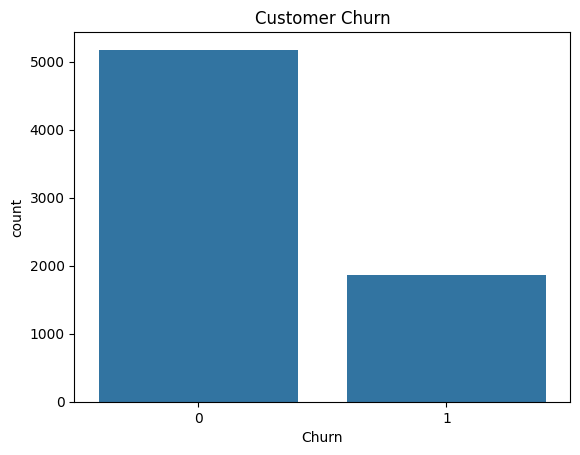

In [20]:
sns.countplot( x = 'Churn' , data= df)
plt.title('Customer Churn')
plt.show()

In [21]:
df['Churn'].value_counts()

Churn
0    5174
1    1869
Name: count, dtype: int64

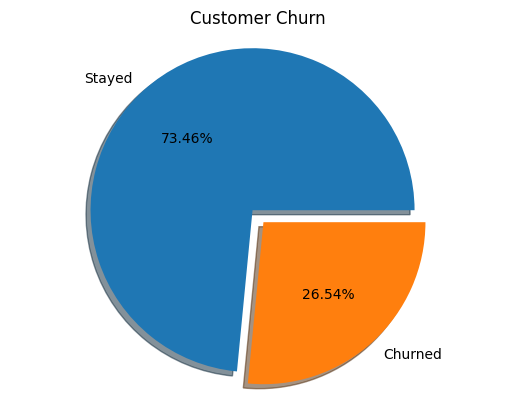

In [22]:
plt.pie(df['Churn'].value_counts() , 
        labels = ('Stayed','Churned') , 
        autopct = '%1.2f%%' , 
        shadow = True , 
        explode = [0 , 0.1])
plt.title('Customer Churn')
plt.axis('equal')
plt.show()

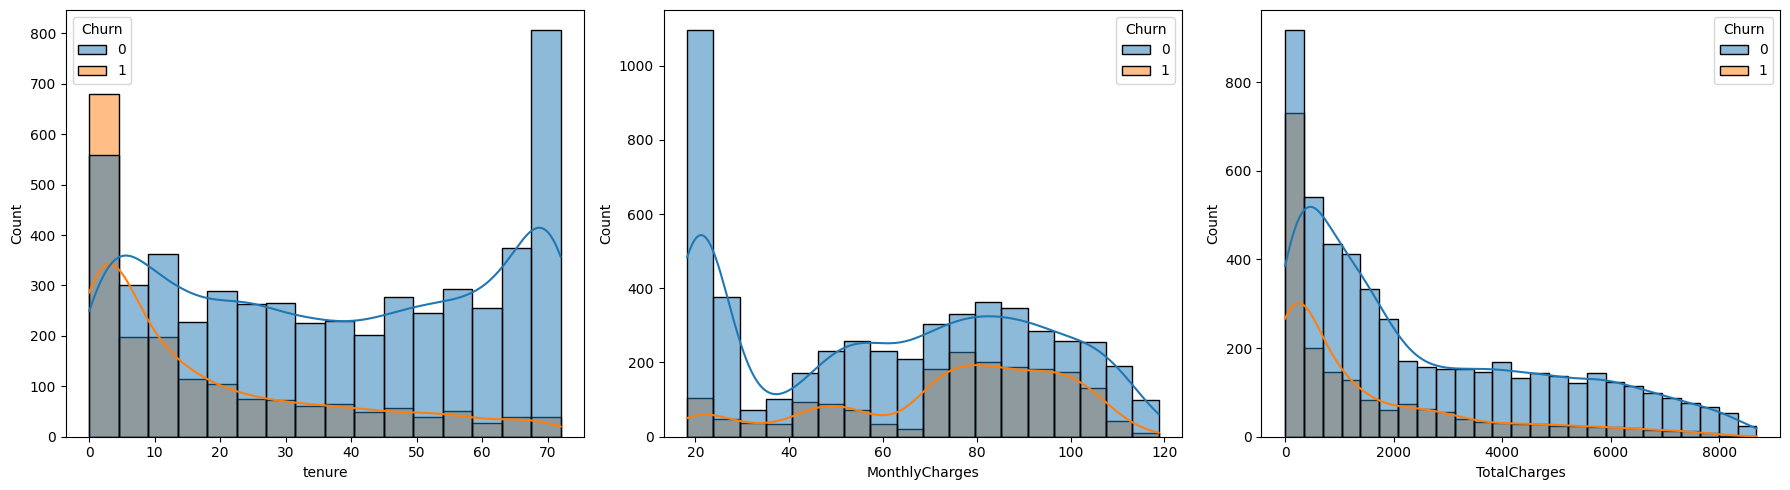

In [23]:
plt.figure(figsize= (18, 5))
for i, col in enumerate(num_cols):
    plt.subplot(1, 3, i + 1)
    sns.histplot(data= df , x= col , hue= 'Churn' , kde= True)
plt.tight_layout()
plt.show()

In [24]:
cat_cols = df.drop(columns= 'Churn').select_dtypes(exclude= 'number').columns.tolist() + ['SeniorCitizen']
len(cat_cols)

16

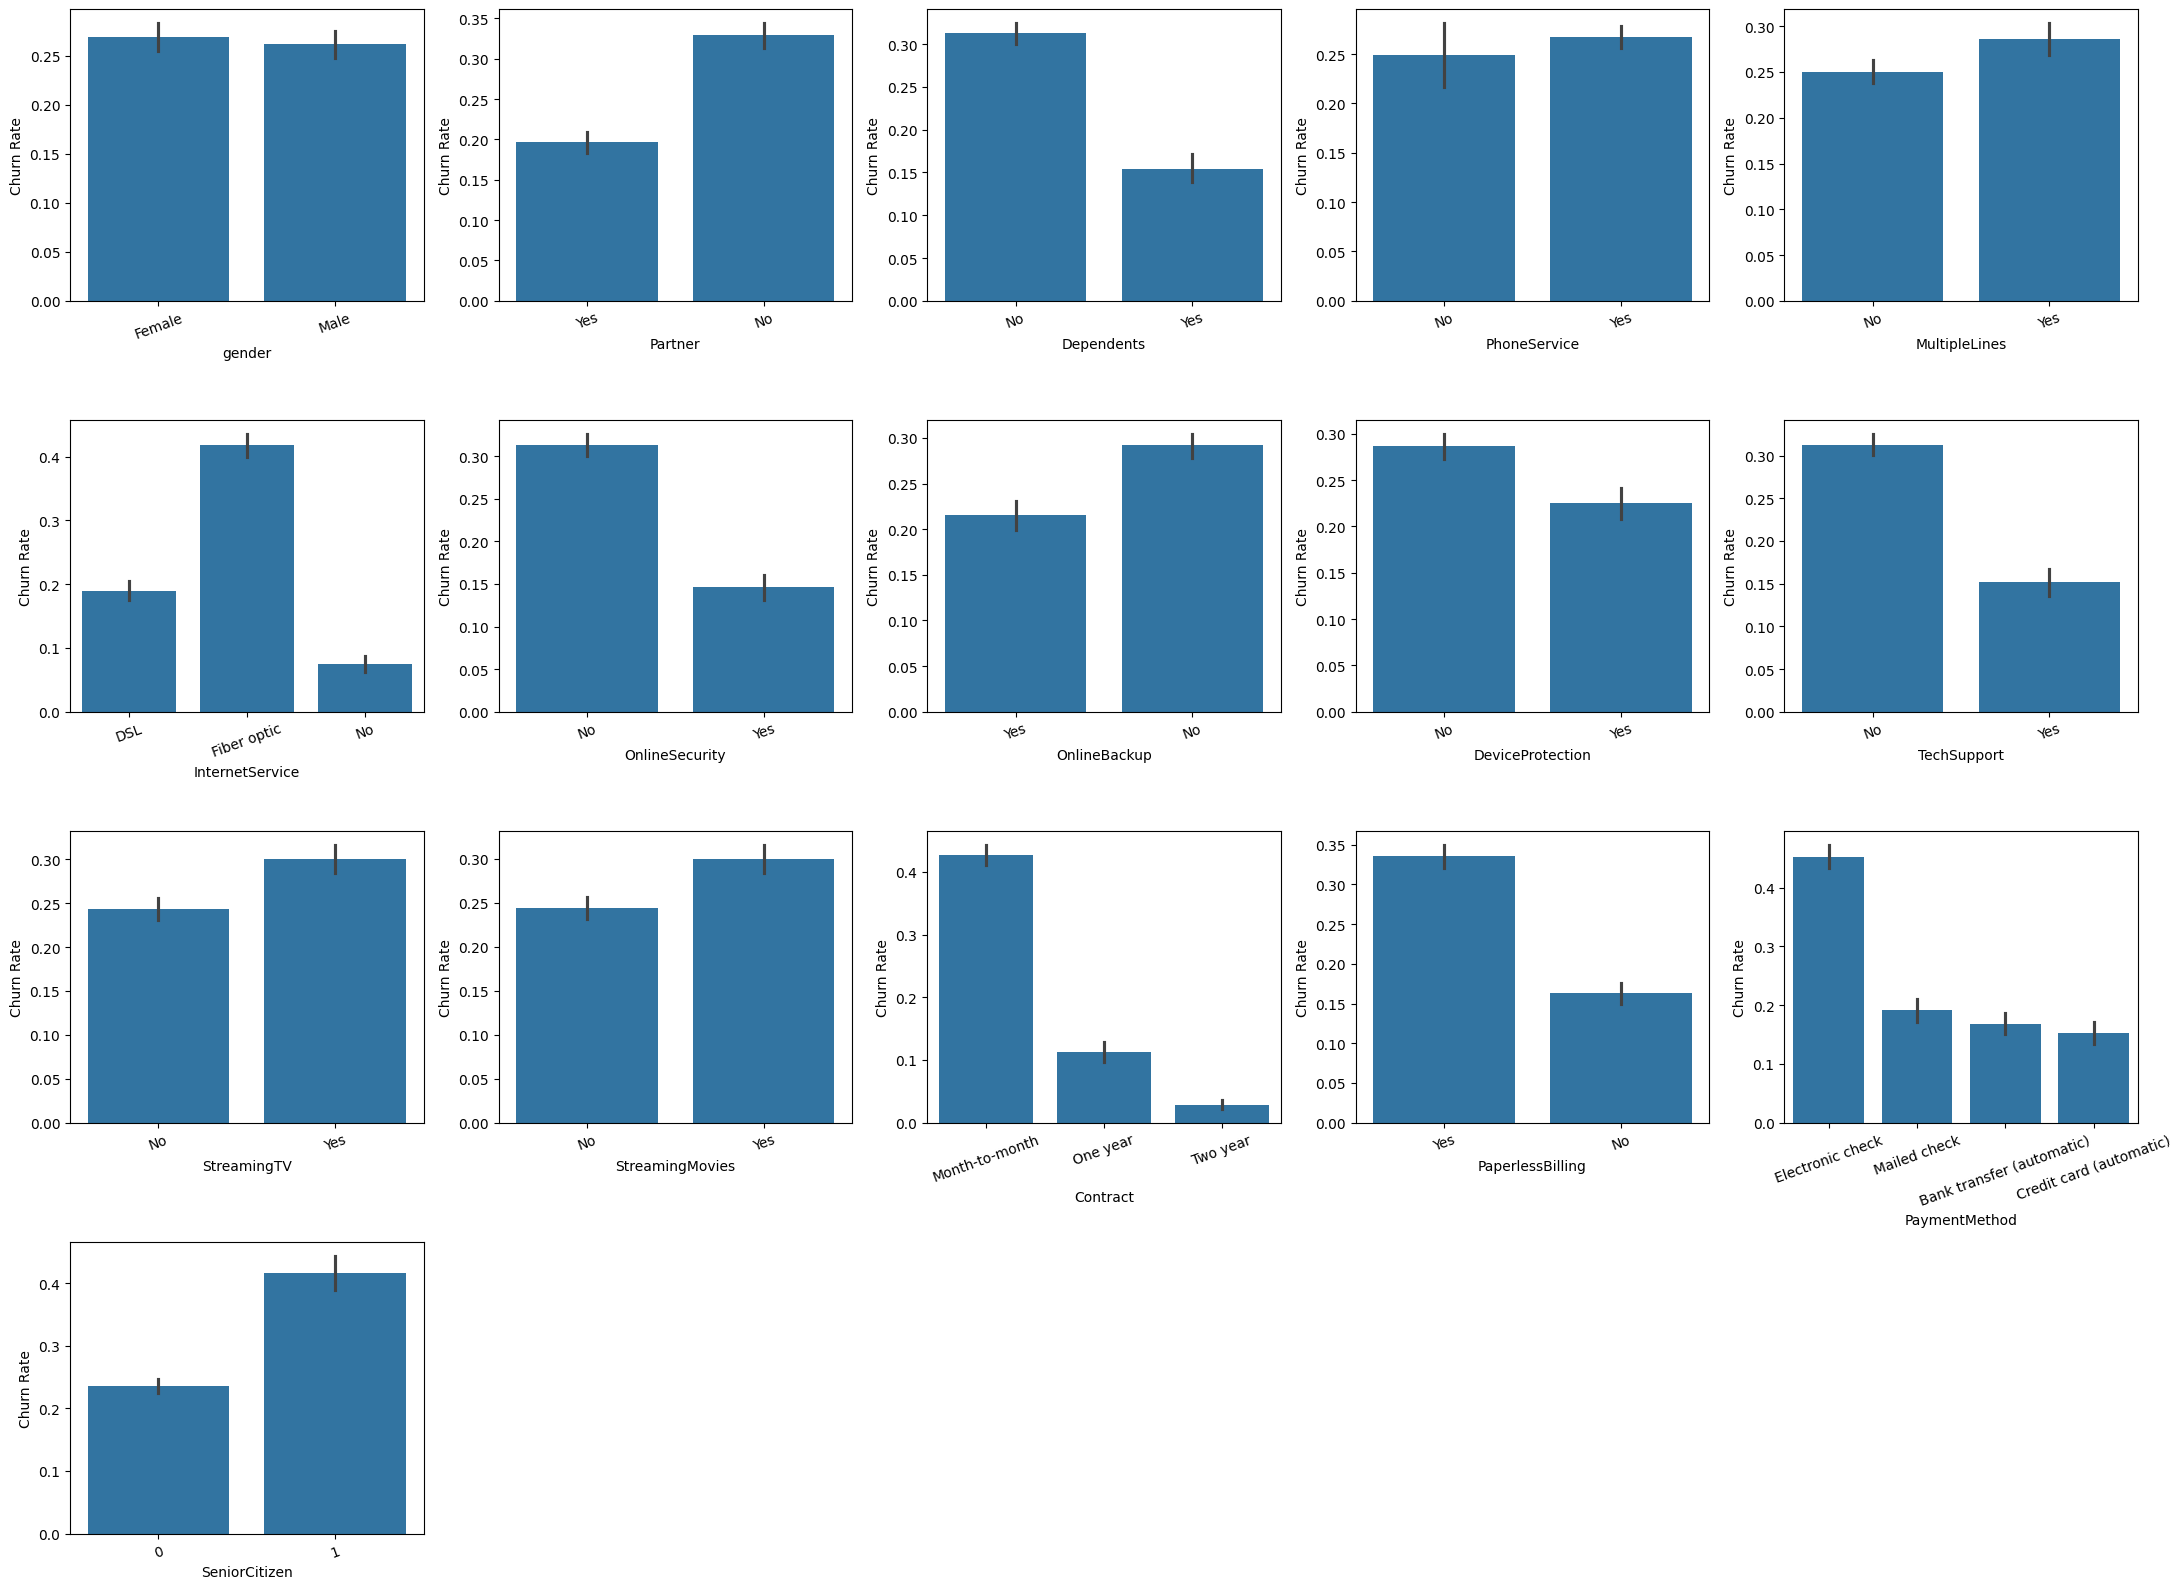

In [25]:
plt.figure(figsize= (22, 16))
for i, col in enumerate(cat_cols):
    plt.subplot(4, 5, i + 1)
    sns.barplot(x= col , y= 'Churn' , data= df)
    plt.ylabel('Churn Rate')
    plt.xticks(rotation= 20)
plt.tight_layout()
plt.show()

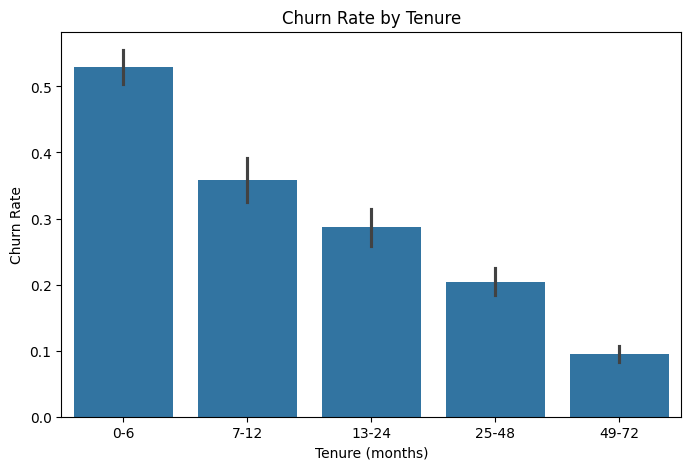

In [26]:
plt.figure(figsize= (8,5))
plt.title('Churn Rate by Tenure')
sns.barplot( x = pd.cut(df['tenure'] , bins= [-1 , 6 , 12 , 24 , 48 , 72] , labels= ['0-6' , '7-12' , '13-24' , '25-48' , '49-72']) , y= df['Churn'])
plt.xlabel('Tenure (months)')
plt.ylabel('Churn Rate')
plt.show()

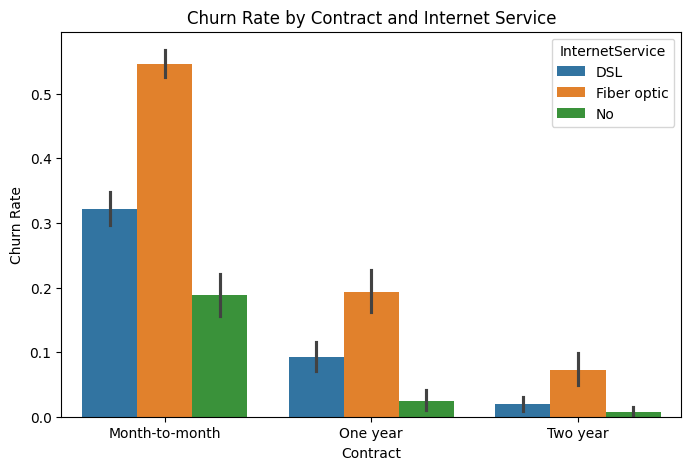

In [27]:
plt.figure(figsize= (8,5))
plt.title('Churn Rate by Contract and Internet Service')
sns.barplot( x = 'Contract' , y= 'Churn' , hue= 'InternetService' , data= df)
plt.ylabel('Churn Rate')
plt.show()

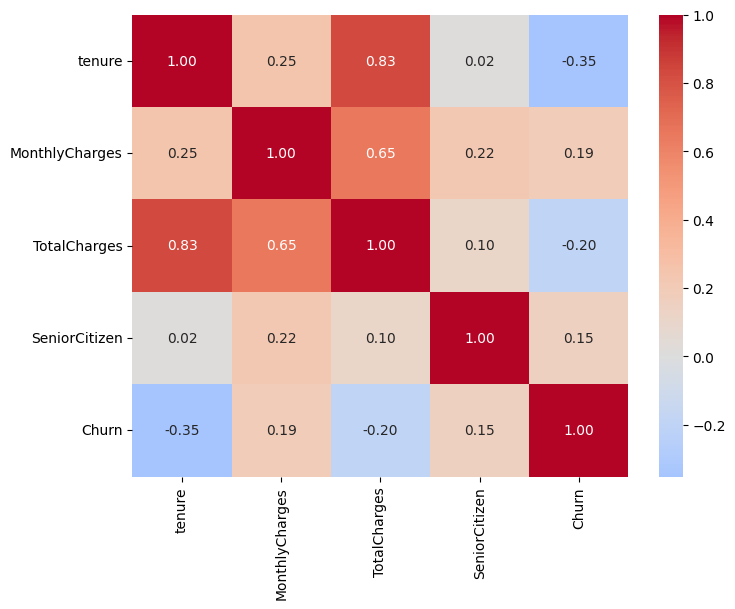

In [28]:
plt.figure(figsize= (8,6))
sns.heatmap (df[num_cols + ['SeniorCitizen' , 'Churn']].corr() , annot= True , fmt= '.2f' , cmap= 'coolwarm' , center= 0)
plt.show()

In [29]:
df[num_cols].skew()

tenure            0.239540
MonthlyCharges   -0.220524
TotalCharges      0.963235
dtype: float64

In [30]:
X = df.drop(columns= 'Churn')
y = df['Churn']

In [31]:
cat_features = X.select_dtypes(exclude= 'number').columns.tolist()
num_features = ['tenure' , 'MonthlyCharges' , 'TotalCharges']

cat_features

['gender',
 'Partner',
 'Dependents',
 'PhoneService',
 'MultipleLines',
 'InternetService',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'Contract',
 'PaperlessBilling',
 'PaymentMethod']

In [32]:
preprocessor = ColumnTransformer([
    ('num' , StandardScaler() , num_features) ,
    ('cat' , OneHotEncoder(drop= 'if_binary' , handle_unknown= 'ignore') , cat_features)
] , remainder= 'passthrough')

### **Train Test Split**

In [33]:
X_train , X_test , y_train , y_test = train_test_split(X , y , test_size= 0.2 , random_state= 42 , stratify= y)

In [34]:
X_train.shape , X_test.shape

((5634, 19), (1409, 19))

In [35]:
y_train.mean() , y_test.mean()

(np.float64(0.2653532126375577), np.float64(0.2654364797728886))

### **Model Training**

In [36]:
models = {
    'Logistic Regression': LogisticRegression(max_iter= 1000 , class_weight= 'balanced') ,
    'KNN': KNeighborsClassifier() ,
    'Random Forest': RandomForestClassifier(class_weight= 'balanced' , random_state= 42 , n_jobs= -1) ,
    'Gradient Boosting': GradientBoostingClassifier(random_state= 42)
}

cv = RepeatedStratifiedKFold(n_splits= 5 , n_repeats= 2 , random_state= 42)

In [37]:
scores = {}
metrics = ['roc_auc' , 'recall' , 'precision' , 'f1' , 'accuracy']
for name, model in models.items():
    pipe = Pipeline([('preprocessor' , preprocessor) , ('model' , model)])
    result = cross_validate(pipe , X_train , y_train , cv= cv , scoring= metrics)
    scores[name] = {metric: result['test_' + metric].mean() for metric in metrics}

baseline = pd.DataFrame(scores).T.sort_values('roc_auc' , ascending= False)
baseline.round(3)

,roc_auc,recall,precision,f1,accuracy
Gradient Boosting,0.848,0.523,0.667,0.585,0.804
Logistic Regression,0.846,0.802,0.519,0.630,0.750
Random Forest,0.828,0.475,0.639,0.544,0.789
KNN,0.783,0.534,0.575,0.553,0.771


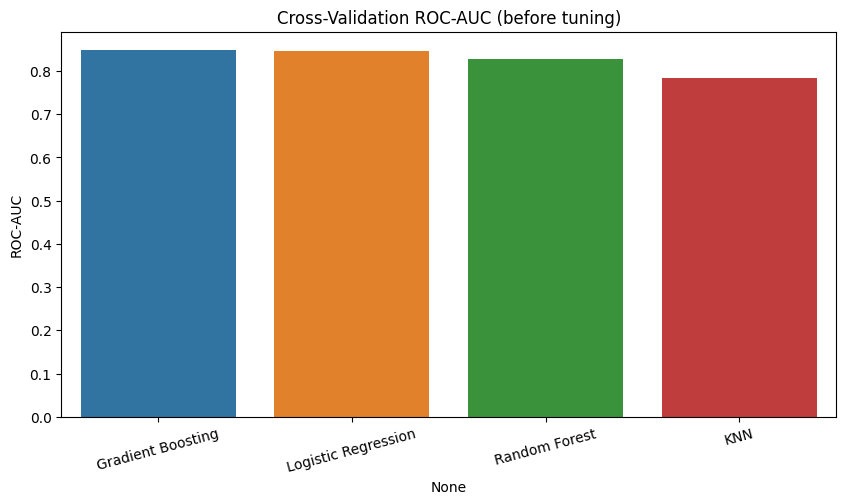

In [38]:
plt.figure(figsize= (10,5))
plt.title('Cross-Validation ROC-AUC (before tuning)')
sns.barplot( x = baseline.index , y= baseline['roc_auc'] , hue= baseline.index)
plt.ylabel('ROC-AUC')
plt.xticks(rotation= 15)
plt.show()

In [39]:
param_grids = {
    'Logistic Regression': {'model__C': [0.01 , 0.1 , 0.5 , 1 , 5]} ,
    'Random Forest': {'model__n_estimators': [300] , 'model__max_depth': [5 , 8 , 12] , 'model__min_samples_leaf': [3 , 5 , 10]} ,
    'Gradient Boosting': {'model__n_estimators': [100 , 200] , 'model__learning_rate': [0.03 , 0.1] , 'model__max_depth': [2 , 3]}
}

grid_results = {}
for name, grid in param_grids.items():
    pipe = Pipeline([('preprocessor' , preprocessor) , ('model' , models[name])])
    grid_results[name] = GridSearchCV(pipe , grid , cv= cv , scoring= 'roc_auc' , n_jobs= -1).fit(X_train , y_train)
    print(name , round(grid_results[name].best_score_ , 4) , grid_results[name].best_params_)

Logistic Regression 0.8463 {'model__C': 5}
Random Forest 0.8486 {'model__max_depth': 8, 'model__min_samples_leaf': 10, 'model__n_estimators': 300}
Gradient Boosting 0.8498 {'model__learning_rate': 0.1, 'model__max_depth': 2, 'model__n_estimators': 100}


In [40]:
best_name = max(grid_results , key= lambda name: grid_results[name].best_score_)
final_model = grid_results[best_name].best_estimator_
best_name

'Gradient Boosting'

In [41]:
oof_prob = cross_val_predict(final_model , X_train , y_train , cv= 5 , method= 'predict_proba')[: , 1]

thresholds = np.arange(0.1 , 0.91 , 0.01)
f1_scores = [f1_score(y_train , oof_prob >= t) for t in thresholds]
best_threshold = thresholds[int(np.argmax(f1_scores))]

best_threshold

np.float64(0.34999999999999987)

### **Model Evaluation**

In [42]:
y_prob = final_model.predict_proba(X_test)[: , 1]
y_pred_default = (y_prob >= 0.5).astype(int)
y_pred_tuned = (y_prob >= best_threshold).astype(int)

print('Threshold 0.5')
print(classification_report(y_test , y_pred_default , target_names= ['Stayed' , 'Churned']))

Threshold 0.5
              precision    recall  f1-score   support

      Stayed       0.83      0.91      0.87      1035
     Churned       0.66      0.50      0.57       374

    accuracy                           0.80      1409
   macro avg       0.75      0.71      0.72      1409
weighted avg       0.79      0.80      0.79      1409



In [43]:
print('Threshold' , round(best_threshold , 2))
print(classification_report(y_test , y_pred_tuned , target_names= ['Stayed' , 'Churned']))

Threshold 0.35
              precision    recall  f1-score   support

      Stayed       0.89      0.80      0.84      1035
     Churned       0.56      0.72      0.63       374

    accuracy                           0.78      1409
   macro avg       0.73      0.76      0.74      1409
weighted avg       0.80      0.78      0.79      1409



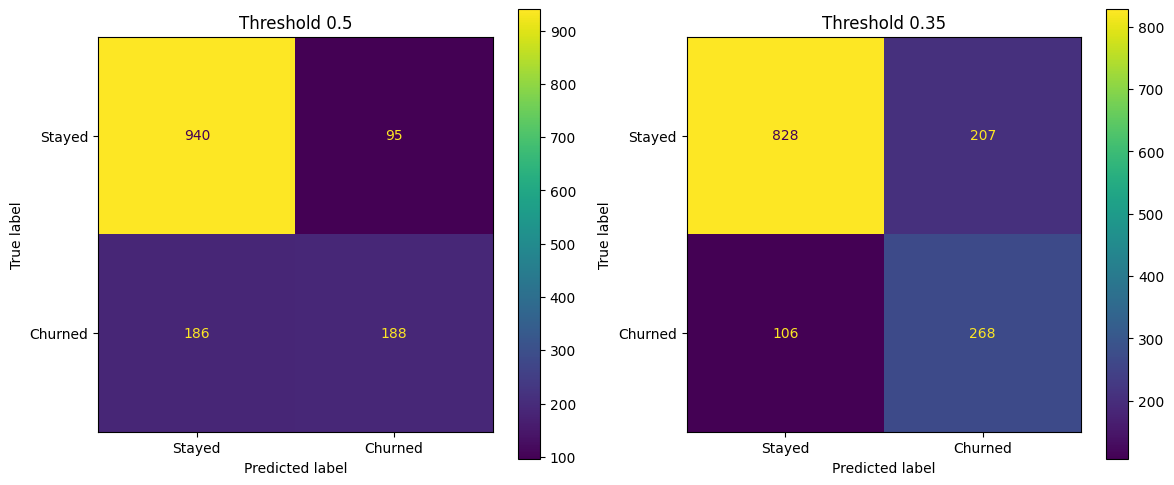

In [44]:
fig , axes = plt.subplots(1 , 2 , figsize= (12 , 5))
ConfusionMatrixDisplay.from_predictions(y_test , y_pred_default , display_labels= ['Stayed' , 'Churned'] , ax= axes[0])
axes[0].set_title('Threshold 0.5')
ConfusionMatrixDisplay.from_predictions(y_test , y_pred_tuned , display_labels= ['Stayed' , 'Churned'] , ax= axes[1])
axes[1].set_title('Threshold ' + str(round(best_threshold , 2)))
plt.tight_layout()
plt.show()

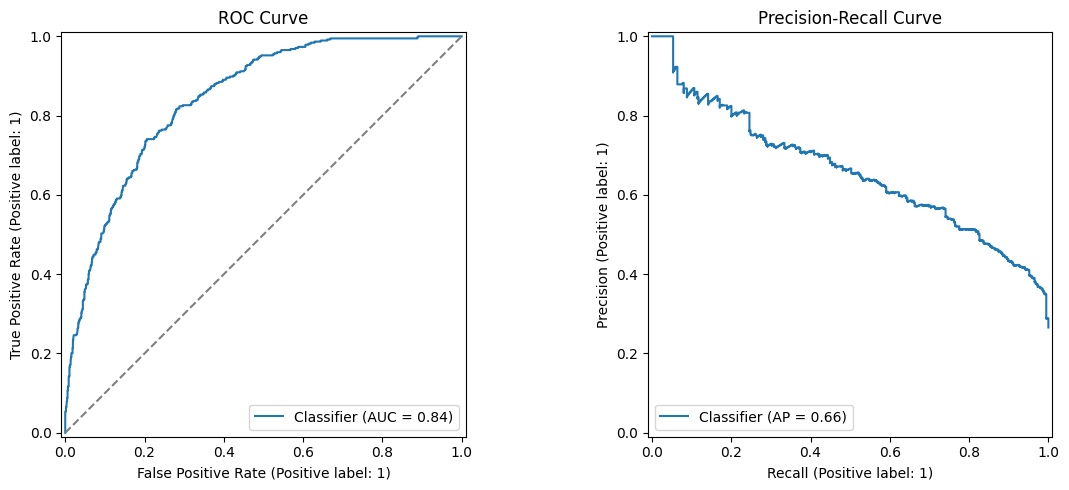

In [45]:
fig , axes = plt.subplots(1 , 2 , figsize= (12 , 5))
RocCurveDisplay.from_predictions(y_test , y_prob , ax= axes[0])
axes[0].plot([0 , 1] , [0 , 1] , ls= '--' , color= 'gray')
axes[0].set_title('ROC Curve')
PrecisionRecallDisplay.from_predictions(y_test , y_prob , ax= axes[1])
axes[1].set_title('Precision-Recall Curve')
plt.tight_layout()
plt.show()

In [46]:
roc_auc_score(y_test , y_prob)

0.844594280399907

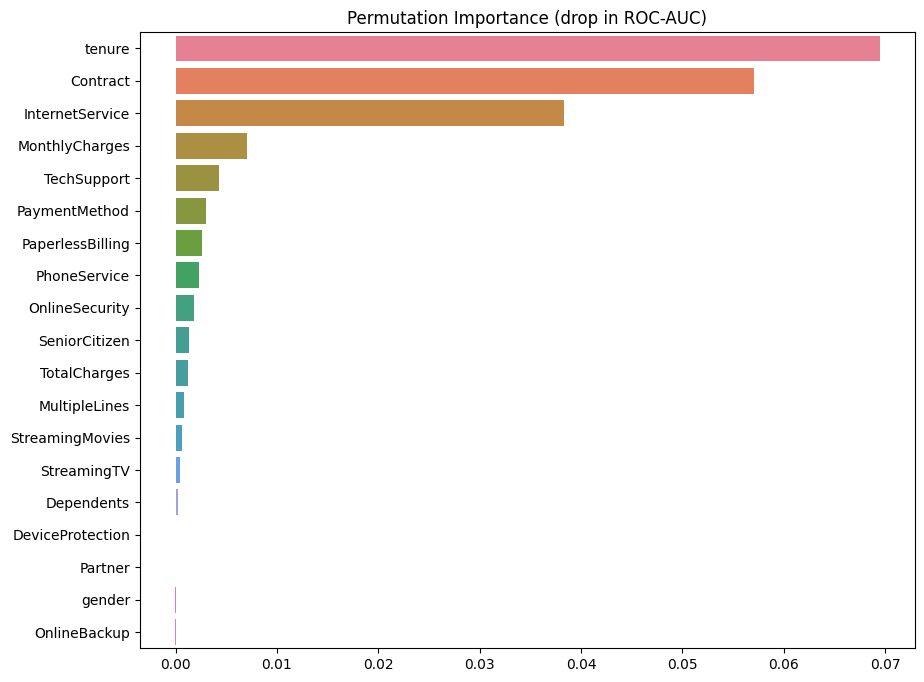

In [47]:
importance = permutation_importance(final_model , X_test , y_test , scoring= 'roc_auc' , n_repeats= 10 , random_state= 42)
importance_df = pd.Series(importance.importances_mean , index= X_test.columns).sort_values(ascending= False)

plt.figure(figsize= (10,8))
plt.title('Permutation Importance (drop in ROC-AUC)')
sns.barplot( x = importance_df.values , y= importance_df.index , hue= importance_df.index)
plt.ylabel('')
plt.show()